# A first surrogate: learn, design, and verify

**Chapter 10 analytical starter.** This notebook uses a synthetic resonant-sheet formula, not a full-wave simulation or measured dataset. The scalar design coordinate has no assigned fabrication geometry. The purpose is to make the data split, learning calculation, inverse search, and verification inspectable.

Read the [chapter](../chapters/10-ai-metasurfaces.md) and [lab instructions](../labs/13-ai-metasurfaces.md). Restart the kernel and run all cells. Edit the parameters below to repeat the experiment. No network access, GPU, or external data is required during execution.

## 1. Environment and editable parameters

All frequencies and linewidths below are normalized by a reference angular frequency. The design coordinate is dimensionless.

In [1]:
import sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

SEED = 24
G_MIN, G_MAX = 0.05, 0.95
N_DESIGNS = 80
N_TRAIN, N_VALID = 40, 20
OMEGA_MIN, OMEGA_MAX, N_OMEGA = 0.8, 1.2, 101
OMEGA0_OFFSET, OMEGA0_SLOPE = 0.9, 0.2
GAMMA_OFFSET, GAMMA_SLOPE = 0.025, 0.02
LENGTH_SCALES = (0.03, 0.06, 0.12, 0.24)
REGULARIZATIONS = (1e-8, 1e-6, 1e-4)
G_TARGET, N_CANDIDATES = 0.623, 901

assert N_TRAIN > 0 and N_VALID > 0 and N_TRAIN + N_VALID < N_DESIGNS
assert G_MIN < G_MAX and OMEGA_MIN < OMEGA_MAX
assert G_MIN <= G_TARGET <= G_MAX
assert N_OMEGA > 2 and N_CANDIDATES > 2
assert all(a > 0 for a in REGULARIZATIONS)
assert all(s > 0 for s in LENGTH_SCALES)
print(f"Python {sys.version.split()[0]}, NumPy {np.__version__}, Matplotlib {matplotlib.__version__}")
print("Evidence: analytical synthetic model; no full-wave or experimental validation.")


Python 3.12.1, NumPy 2.4.6, Matplotlib 3.11.1
Evidence: analytical synthetic model; no full-wave or experimental validation.


## 2. Define and check the forward generator

For the $e^{-i\omega t}$ convention and a symmetric lossless two-port model in equal media,

$$r=-\frac{\gamma}{\gamma-i\Delta},\qquad t=1+r,\qquad\Delta=\Omega-\Omega_0.$$

The design mapping is $\Omega_0=0.9+0.2g$ and $\gamma=0.025+0.02g$. These choices are teaching assumptions. Both $R+T=1$ and the resonance values can be checked independently from the algebra.

In [2]:
def resonant_sheet(g, omega):
    """Return complex (r, t), with shape (number of designs, frequencies)."""
    g = np.atleast_1d(np.asarray(g, dtype=float))[:, None]
    omega = np.atleast_1d(np.asarray(omega, dtype=float))[None, :]
    omega0 = OMEGA0_OFFSET + OMEGA0_SLOPE * g
    gamma = GAMMA_OFFSET + GAMMA_SLOPE * g
    if np.any(gamma <= 0):
        raise ValueError("Linewidth must be positive")
    delta = omega - omega0
    r = -gamma / (gamma - 1j * delta)
    return r, 1 + r

omega = np.linspace(OMEGA_MIN, OMEGA_MAX, N_OMEGA)
g_all = np.linspace(G_MIN, G_MAX, N_DESIGNS)
r_all, t_all = resonant_sheet(g_all, omega)
power_residual = np.max(np.abs(np.abs(r_all)**2 + np.abs(t_all)**2 - 1))
assert power_residual < 1e-12
g_check = 0.5 * (G_MIN + G_MAX)
r0, t0 = resonant_sheet(g_check, OMEGA0_OFFSET + OMEGA0_SLOPE * g_check)
assert np.allclose(r0, -1) and np.allclose(t0, 0)
print(f"Maximum analytical power-balance residual: {power_residual:.3e}")
print("Resonance check passed: r = -1 and t = 0.")


Maximum analytical power-balance residual: 5.551e-16
Resonance check passed: r = -1 and t = 0.


## 3. Split whole designs

Each row contains a complete complex spectrum. We split geometry IDs, so frequencies belonging to one design cannot leak across sets. The validation set chooses model settings. The test set remains unused until the model choice is fixed. This experiment tests interpolation within the sampled design interval, not out-of-domain generalization.

In [3]:
rng = np.random.default_rng(SEED)
ids = rng.permutation(N_DESIGNS)
train_ids = np.sort(ids[:N_TRAIN])
valid_ids = np.sort(ids[N_TRAIN:N_TRAIN + N_VALID])
test_ids = np.sort(ids[N_TRAIN + N_VALID:])
assert not (set(train_ids) & set(valid_ids) or set(train_ids) & set(test_ids) or set(valid_ids) & set(test_ids))
assert set(np.concatenate((train_ids, valid_ids, test_ids))) == set(range(N_DESIGNS))
g_train, y_train = g_all[train_ids], t_all[train_ids]
print("Training IDs:", train_ids.tolist())
print("Validation IDs:", valid_ids.tolist())
print("Test IDs:", test_ids.tolist())


Training IDs: [0, 6, 7, 8, 11, 17, 22, 23, 25, 29, 31, 32, 33, 35, 36, 37, 38, 41, 42, 45, 49, 52, 53, 54, 56, 57, 58, 59, 61, 62, 63, 65, 66, 67, 68, 73, 75, 76, 77, 78]
Validation IDs: [1, 2, 4, 10, 13, 16, 20, 21, 30, 34, 40, 43, 44, 46, 48, 50, 51, 69, 74, 79]
Test IDs: [3, 5, 9, 12, 14, 15, 18, 19, 24, 26, 27, 28, 39, 47, 55, 60, 64, 70, 71, 72]


## 4. Fit a baseline and a kernel surrogate

Nearest-neighbor retrieval returns the entire spectrum of the closest training design. Kernel ridge regression uses

$$K_{ij}=\exp[-(g_i-g_j)^2/(2\ell^2)],\quad (K+\alpha I)A=Y.$$

We solve this system for complex spectral columns. There is no test-set preprocessing or tuning. The implementation uses only NumPy so that every operation can be inspected.

In [4]:
def kernel(a, b, length_scale):
    distance = np.atleast_1d(a)[:, None] - np.atleast_1d(b)[None, :]
    return np.exp(-0.5 * (distance / length_scale)**2)

def complex_rmse(predicted, reference):
    return float(np.sqrt(np.mean(np.abs(predicted - reference)**2)))

def nearest_predict(g):
    nearest = np.argmin(np.abs(np.atleast_1d(g)[:, None] - g_train[None, :]), axis=1)
    return y_train[nearest]

trials = []
for length_scale in LENGTH_SCALES:
    for alpha in REGULARIZATIONS:
        weights = np.linalg.solve(kernel(g_train, g_train, length_scale) + alpha*np.eye(N_TRAIN), y_train)
        prediction = kernel(g_all[valid_ids], g_train, length_scale) @ weights
        trials.append((complex_rmse(prediction, t_all[valid_ids]), length_scale, alpha))
valid_rmse, best_length_scale, best_alpha = min(trials)
weights = np.linalg.solve(kernel(g_train, g_train, best_length_scale) + best_alpha*np.eye(N_TRAIN), y_train)

def surrogate_predict(g):
    return kernel(np.atleast_1d(g), g_train, best_length_scale) @ weights

print(f"Validation selected length scale={best_length_scale}, alpha={best_alpha:g}")
print(f"Validation complex RMSE={valid_rmse:.6g}")


Validation selected length scale=0.12, alpha=1e-08
Validation complex RMSE=0.000643005


## 5. Evaluate held-out designs

The complex RMSE is dimensionless. The power error below refers to absolute transmission fractions, not a relative percentage error. Because the generator obeys `r = t - 1`, we can diagnose power imbalance after reconstructing reflection from a predicted transmission. That reconstruction does not make the regression automatically lossless.

In [5]:
y_test = t_all[test_ids]
nearest_test = nearest_predict(g_all[test_ids])
surrogate_test = surrogate_predict(g_all[test_ids])
assert np.isfinite(surrogate_test).all()
test_metrics = {}
for name, prediction in [("Nearest neighbor", nearest_test), ("Kernel ridge", surrogate_test)]:
    rmse = complex_rmse(prediction, y_test)
    power_mae = float(np.mean(np.abs(np.abs(prediction)**2 - np.abs(y_test)**2)))
    max_balance_error = float(np.max(np.abs(np.abs(prediction - 1)**2 + np.abs(prediction)**2 - 1)))
    test_metrics[name] = {"complex_rmse": rmse, "transmission_power_mae": power_mae, "max_power_balance_error": max_balance_error}
    print(f"{name:17s} complex RMSE={rmse:.6g}; power MAE={power_mae:.6g}; max balance residual={max_balance_error:.6g}")

# A phase-wrap diagnostic, separate from the regression comparison.
reference = np.exp(1j*np.deg2rad(179))
prediction = np.exp(1j*np.deg2rad(-179))
circular_error = np.rad2deg(np.angle(prediction*np.conj(reference)))
print(f"Phase example: ordinary difference = {-179-179} degrees; circular difference = {circular_error:.1f} degrees")


Nearest neighbor  complex RMSE=0.0413522; power MAE=0.0163445; max balance residual=4.44089e-16
Kernel ridge      complex RMSE=0.000353376; power MAE=7.65072e-05; max balance residual=0.00913201
Phase example: ordinary difference = -358 degrees; circular difference = 2.0 degrees


## 6. Propose an inverse design, then verify it

The target comes from a known feasible design, but its coordinate is used only to generate the target and later interpret the result. The search minimizes mean squared complex transmission error over a bounded grid using the surrogate. We then call the exact analytical generator at the selected design.

Agreement with this generator checks surrogate error. It does not establish a physical realization, full-wave accuracy, or global optimality in a continuous design space.

In [6]:
_, target = resonant_sheet(G_TARGET, omega)
g_candidates = np.linspace(G_MIN, G_MAX, N_CANDIDATES)
candidate_predictions = surrogate_predict(g_candidates)
objective = np.mean(np.abs(candidate_predictions - target)**2, axis=1)
selected_index = int(np.argmin(objective))
g_selected = float(g_candidates[selected_index])
predicted_selected = candidate_predictions[selected_index:selected_index+1]
r_verified, t_verified = resonant_sheet(g_selected, omega)
predicted_target_rmse = complex_rmse(predicted_selected, target)
verified_target_rmse = complex_rmse(t_verified, target)
grid_spacing = float(g_candidates[1]-g_candidates[0])
assert np.isfinite(objective).all() and G_MIN <= g_selected <= G_MAX
assert np.max(np.abs(np.abs(r_verified)**2 + np.abs(t_verified)**2 - 1)) < 1e-12
print(f"Target generator coordinate: {G_TARGET:.6f}")
print(f"Selected coordinate: {g_selected:.6f}; grid spacing: {grid_spacing:.6f}")
print(f"Surrogate target RMSE: {predicted_target_rmse:.6g}")
print(f"Analytically verified target RMSE: {verified_target_rmse:.6g}")


Target generator coordinate: 0.623000
Selected coordinate: 0.623000; grid spacing: 0.001000
Surrogate target RMSE: 3.2859e-05
Analytically verified target RMSE: 0


## 7. Inspect the evidence

Inspect both spectral shape and error distributions. If the inverse curves nearly coincide, use the numerical errors printed above rather than interpreting line overlap as exact equality. This one-dimensional synthetic problem is intentionally small; it is not a performance benchmark for a high-dimensional metasurface design.

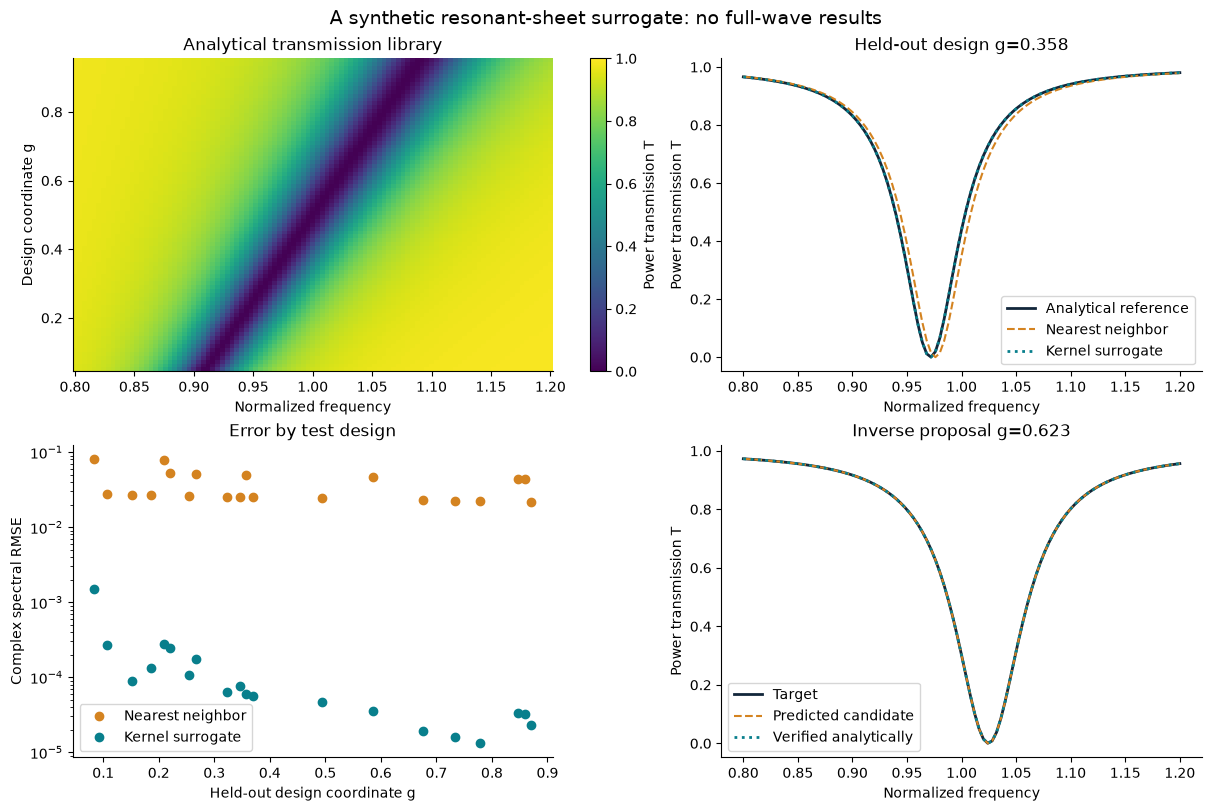

In [7]:
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
ax = axes[0, 0]
im = ax.pcolormesh(omega, g_all, np.abs(t_all)**2, shading="auto", cmap="viridis", vmin=0, vmax=1)
ax.set(xlabel="Normalized frequency", ylabel="Design coordinate g", title="Analytical transmission library")
fig.colorbar(im, ax=ax, label="Power transmission T")

example = len(test_ids)//2
ax = axes[0, 1]
ax.plot(omega, np.abs(y_test[example])**2, color="#12263a", label="Analytical reference", linewidth=2)
ax.plot(omega, np.abs(nearest_test[example])**2, '--', color="#d48320", label="Nearest neighbor")
ax.plot(omega, np.abs(surrogate_test[example])**2, ':', color="#087f8c", label="Kernel surrogate", linewidth=2)
ax.set(xlabel="Normalized frequency", ylabel="Power transmission T", title=f"Held-out design g={g_all[test_ids[example]]:.3f}")
ax.legend()

ax = axes[1, 0]
for label, prediction, color in [("Nearest neighbor", nearest_test, "#d48320"), ("Kernel surrogate", surrogate_test, "#087f8c")]:
    error = np.sqrt(np.mean(np.abs(prediction-y_test)**2, axis=1))
    ax.semilogy(g_all[test_ids], np.maximum(error, 1e-16), 'o', label=label, color=color)
ax.set(xlabel="Held-out design coordinate g", ylabel="Complex spectral RMSE", title="Error by test design")
ax.legend()

ax = axes[1, 1]
ax.plot(omega, np.abs(target[0])**2, color="#12263a", label="Target", linewidth=2)
ax.plot(omega, np.abs(predicted_selected[0])**2, '--', color="#d48320", label="Predicted candidate")
ax.plot(omega, np.abs(t_verified[0])**2, ':', color="#087f8c", label="Verified analytically", linewidth=2)
ax.set(xlabel="Normalized frequency", ylabel="Power transmission T", title=f"Inverse proposal g={g_selected:.3f}")
ax.legend()
fig.suptitle("A synthetic resonant-sheet surrogate: no full-wave results", fontsize=14)
plt.show()


## 8. Extensions and report

1. Reduce the training count and repeat the complete split/selection/test procedure. Compare learning curves across several seeds.
2. Replace the random geometry split with a deliberately withheld interval. Label this result separately from the interpolation test.
3. Remove part of the resonance band from the measured outputs. Discuss whether the inverse target remains identifiable.
4. Examine circular phase errors only above a declared amplitude threshold, and also report amplitude error and the excluded fraction.
5. Add numerical or measurement noise with a documented model. Repeat selection of the regularization parameter.
6. Replace this generator with a converged full-wave unit-cell dataset as described in Stage B of the lab. Preserve geometry IDs, normalization, solver settings, and reference planes.

Report the split IDs, environment, seed, hyperparameters, test errors, candidate bounds/grid spacing, and predicted-versus-verified target errors. Explain the limits of each claim. The learning calculation does not run in the static web page; download the notebook to modify and execute it.
